
# Sales Forecasting Using Machine Learning

## Objective
Predict daily delivered recorded sales amounts using historical sales data.

## Machine Learning Workflow
1. Load and prepare data
2. Explore the daily sales trend
3. Create forecasting features
4. Split data chronologically
5. Train a baseline and machine learning models
6. Evaluate models using MAE and RMSE
7. Generate future forecasts


## Load and prepare the data

In [1]:

# Import the libraries required for data preparation
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load the original sales dataset
sales = pd.read_csv("../data/sales.csv")

# Convert Order_Date from text to datetime
sales["Order_Date"] = pd.to_datetime(sales["Order_Date"])

# Keep delivered orders only
delivered_sales = sales[
    sales["Order_Status"] == "Delivered"
].copy()

# Aggregate delivered recorded amounts by order date
daily_sales = (
    delivered_sales
    .groupby("Order_Date")["Total_Amount"]
    .sum()
    .reset_index()
    .rename(columns={"Total_Amount": "Daily_Sales"})
)

# Create a complete daily calendar for the dataset's date range
date_range = pd.date_range(
    start=sales["Order_Date"].min(),
    end=sales["Order_Date"].max(),
    freq="D"
)

# Add any missing dates to ensure a continuous time series
daily_sales = (
    daily_sales.set_index("Order_Date")
    .reindex(date_range, fill_value=0)
    .rename_axis("Order_Date")
    .reset_index()
)

# Display the dataset summary
print("Daily dataset shape:", daily_sales.shape)
print("Start date:", daily_sales["Order_Date"].min().date())
print("End date:", daily_sales["Order_Date"].max().date())
print("Total delivered recorded amount:",
      round(daily_sales["Daily_Sales"].sum(), 2))

display(daily_sales.head())


Daily dataset shape: (760, 2)
Start date: 2024-06-01
End date: 2026-06-30
Total delivered recorded amount: 4741566354.41


,Order_Date,Daily_Sales
0,2024-06-01,6704620.83
1,2024-06-02,6347543.90
2,2024-06-03,5984976.05
3,2024-06-04,5847043.56
4,2024-06-05,5827407.17


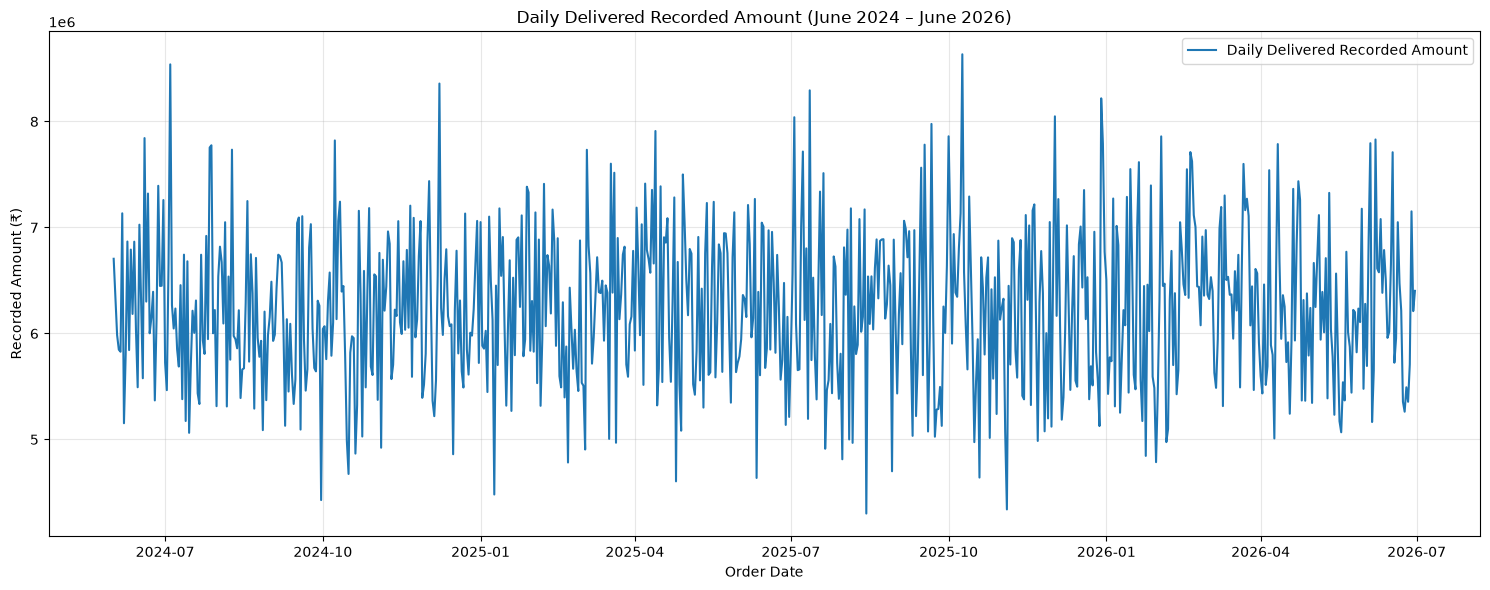

,Daily_Sales
count,7.600000e+02
mean,6.238903e+06
std,7.293291e+05
min,4.300694e+06
25%,5.692513e+06
50%,6.217706e+06
75%,6.757620e+06
max,8.634094e+06


In [2]:

# Create a line chart of daily delivered recorded amounts
plt.figure(figsize=(15, 6))

plt.plot(
    daily_sales["Order_Date"],
    daily_sales["Daily_Sales"],
    label="Daily Delivered Recorded Amount"
)

# Add chart title and axis labels
plt.title("Daily Delivered Recorded Amount (June 2024 – June 2026)")
plt.xlabel("Order Date")
plt.ylabel("Recorded Amount (₹)")

# Improve readability
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()

plt.show()

# Print descriptive statistics to understand the distribution
display(daily_sales["Daily_Sales"].describe().to_frame("Daily_Sales"))


## Create time-series features

In [3]:

# Work on a copy to preserve the original daily dataset
forecast_df = daily_sales.copy()

# Calendar features: help the model learn recurring date patterns
forecast_df["Day_Of_Week"] = forecast_df["Order_Date"].dt.dayofweek
forecast_df["Day_Of_Month"] = forecast_df["Order_Date"].dt.day
forecast_df["Month"] = forecast_df["Order_Date"].dt.month
forecast_df["Quarter"] = forecast_df["Order_Date"].dt.quarter
forecast_df["Is_Weekend"] = (
    forecast_df["Day_Of_Week"] >= 5
).astype(int)

# Lag features: use sales from earlier days to predict the current day
forecast_df["Sales_Lag_1"] = forecast_df["Daily_Sales"].shift(1)
forecast_df["Sales_Lag_7"] = forecast_df["Daily_Sales"].shift(7)
forecast_df["Sales_Lag_14"] = forecast_df["Daily_Sales"].shift(14)
forecast_df["Sales_Lag_30"] = forecast_df["Daily_Sales"].shift(30)

# Rolling features: summarize recent historical sales
# Shift first so today's target is not included in today's rolling mean
forecast_df["Rolling_Mean_7"] = (
    forecast_df["Daily_Sales"].shift(1).rolling(window=7).mean()
)
forecast_df["Rolling_Mean_30"] = (
    forecast_df["Daily_Sales"].shift(1).rolling(window=30).mean()
)

# Show the feature table and missing-value counts
display(forecast_df.head(10))

print("\nMissing values in each column:")
display(forecast_df.isnull().sum().to_frame("Missing_Count"))

print("\nFeature dataset shape:", forecast_df.shape)


,Order_Date,Daily_Sales,Day_Of_Week,Day_Of_Month,Month,Quarter,Is_Weekend,Sales_Lag_1,Sales_Lag_7,Sales_Lag_14,Sales_Lag_30,Rolling_Mean_7,Rolling_Mean_30
0,2024-06-01,6704620.83,5,1,6,2,1,NaN,NaN,NaN,NaN,NaN,NaN
1,2024-06-02,6347543.90,6,2,6,2,1,6704620.83,NaN,NaN,NaN,NaN,NaN
2,2024-06-03,5984976.05,0,3,6,2,0,6347543.90,NaN,NaN,NaN,NaN,NaN
3,2024-06-04,5847043.56,1,4,6,2,0,5984976.05,NaN,NaN,NaN,NaN,NaN
4,2024-06-05,5827407.17,2,5,6,2,0,5847043.56,NaN,NaN,NaN,NaN,NaN
5,2024-06-06,7133566.97,3,6,6,2,0,5827407.17,NaN,NaN,NaN,NaN,NaN
6,2024-06-07,5152835.85,4,7,6,2,0,7133566.97,NaN,NaN,NaN,NaN,NaN
7,2024-06-08,5801092.00,5,8,6,2,1,5152835.85,6704620.83,NaN,NaN,6.142571e+06,NaN
8,2024-06-09,6867397.19,6,9,6,2,1,5801092.00,6347543.90,NaN,NaN,6.013495e+06,NaN
9,2024-06-10,5843193.38,0,10,6,2,0,6867397.19,5984976.05,NaN,NaN,6.087760e+06,NaN



Missing values in each column:


,Missing_Count
Order_Date,0
Daily_Sales,0
Day_Of_Week,0
Day_Of_Month,0
Month,0
Quarter,0
Is_Weekend,0
Sales_Lag_1,1
Sales_Lag_7,7
Sales_Lag_14,14



Feature dataset shape: (760, 13)


In [4]:

# Define the features the model will use
feature_columns = [
    "Day_Of_Week",
    "Day_Of_Month",
    "Month",
    "Quarter",
    "Is_Weekend",
    "Sales_Lag_1",
    "Sales_Lag_7",
    "Sales_Lag_14",
    "Sales_Lag_30",
    "Rolling_Mean_7",
    "Rolling_Mean_30"
]

# Remove rows where historical features are unavailable
model_df = forecast_df.dropna(
    subset=feature_columns + ["Daily_Sales"]
).copy()

# Sort chronologically to prevent future observations entering training
model_df = model_df.sort_values("Order_Date").reset_index(drop=True)

# Use the first 80% of usable dates for training
split_index = int(len(model_df) * 0.80)

train_df = model_df.iloc[:split_index].copy()
test_df = model_df.iloc[split_index:].copy()

# Separate features (X) from the target (y)
X_train = train_df[feature_columns]
y_train = train_df["Daily_Sales"]

X_test = test_df[feature_columns]
y_test = test_df["Daily_Sales"]

# Verify the split
print("Usable records:", len(model_df))
print("Training records:", len(train_df))
print("Testing records:", len(test_df))

print("\nTraining period:")
print(train_df["Order_Date"].min().date(), "to",
      train_df["Order_Date"].max().date())

print("\nTesting period:")
print(test_df["Order_Date"].min().date(), "to",
      test_df["Order_Date"].max().date())

print("\nNo date overlap:",
      train_df["Order_Date"].max() < test_df["Order_Date"].min())

print("\nTraining feature shape:", X_train.shape)
print("Testing feature shape:", X_test.shape)


Usable records: 730
Training records: 584
Testing records: 146

Training period:
2024-07-01 to 2026-02-04

Testing period:
2026-02-05 to 2026-06-30

No date overlap: True

Training feature shape: (584, 11)
Testing feature shape: (146, 11)


## Build a baseline model

In [5]:

# Baseline: predict today's sales using the previous day's actual sales
y_pred_baseline = X_test["Sales_Lag_1"]

# Import evaluation metrics
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# Calculate MAE and RMSE
baseline_mae = mean_absolute_error(y_test, y_pred_baseline)

baseline_rmse = np.sqrt(
    mean_squared_error(y_test, y_pred_baseline)
)

# Display the baseline performance
print("NAIVE BASELINE MODEL")
print("-" * 35)
print(f"MAE:  ₹{baseline_mae:,.2f}")
print(f"RMSE: ₹{baseline_rmse:,.2f}")


NAIVE BASELINE MODEL
-----------------------------------
MAE:  ₹711,757.66
RMSE: ₹890,562.24


## Train a Linear Regression model

In [6]:

# Import Linear Regression
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# Initialize the model
linear_model = LinearRegression()

# Train using the training period only
linear_model.fit(X_train, y_train)

# Predict recorded amounts for the test period
y_pred_linear = linear_model.predict(X_test)

# Evaluate model performance
linear_mae = mean_absolute_error(y_test, y_pred_linear)
linear_rmse = np.sqrt(mean_squared_error(y_test, y_pred_linear))

print("LINEAR REGRESSION MODEL")
print("-" * 35)
print(f"MAE:  ₹{linear_mae:,.2f}")
print(f"RMSE: ₹{linear_rmse:,.2f}")

# Compare with the naive baseline
comparison = pd.DataFrame({
    "Model": ["Naive Baseline", "Linear Regression"],
    "MAE": [baseline_mae, linear_mae],
    "RMSE": [baseline_rmse, linear_rmse]
})

display(comparison.round(2))

# Calculate improvement in MAE relative to the baseline
mae_improvement = (
    (baseline_mae - linear_mae) / baseline_mae
) * 100

print(f"MAE improvement vs baseline: {mae_improvement:.2f}%")


LINEAR REGRESSION MODEL
-----------------------------------
MAE:  ₹574,012.64
RMSE: ₹705,210.54


,Model,MAE,RMSE
0,Naive Baseline,711757.66,890562.24
1,Linear Regression,574012.64,705210.54


MAE improvement vs baseline: 19.35%


## Train a Random Forest model

In [7]:

# Import Random Forest Regressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd

# Initialize a Random Forest model
# random_state makes the results reproducible
rf_model = RandomForestRegressor(
    n_estimators=200,
    max_depth=10,
    min_samples_leaf=3,
    random_state=42,
    n_jobs=-1
)

# Train on the training period only
rf_model.fit(X_train, y_train)

# Predict on the held-out test period
y_pred_rf = rf_model.predict(X_test)

# Evaluate predictions
rf_mae = mean_absolute_error(y_test, y_pred_rf)
rf_rmse = np.sqrt(mean_squared_error(y_test, y_pred_rf))

print("RANDOM FOREST MODEL")
print("-" * 35)
print(f"MAE:  ₹{rf_mae:,.2f}")
print(f"RMSE: ₹{rf_rmse:,.2f}")

# Compare all models evaluated so far
model_comparison = pd.DataFrame({
    "Model": [
        "Naive Baseline",
        "Linear Regression",
        "Random Forest"
    ],
    "MAE": [
        baseline_mae,
        linear_mae,
        rf_mae
    ],
    "RMSE": [
        baseline_rmse,
        linear_rmse,
        rf_rmse
    ]
})

display(model_comparison.round(2))


RANDOM FOREST MODEL
-----------------------------------
MAE:  ₹579,183.15
RMSE: ₹710,904.23


,Model,MAE,RMSE
0,Naive Baseline,711757.66,890562.24
1,Linear Regression,574012.64,705210.54
2,Random Forest,579183.15,710904.23


## Visualize model performance

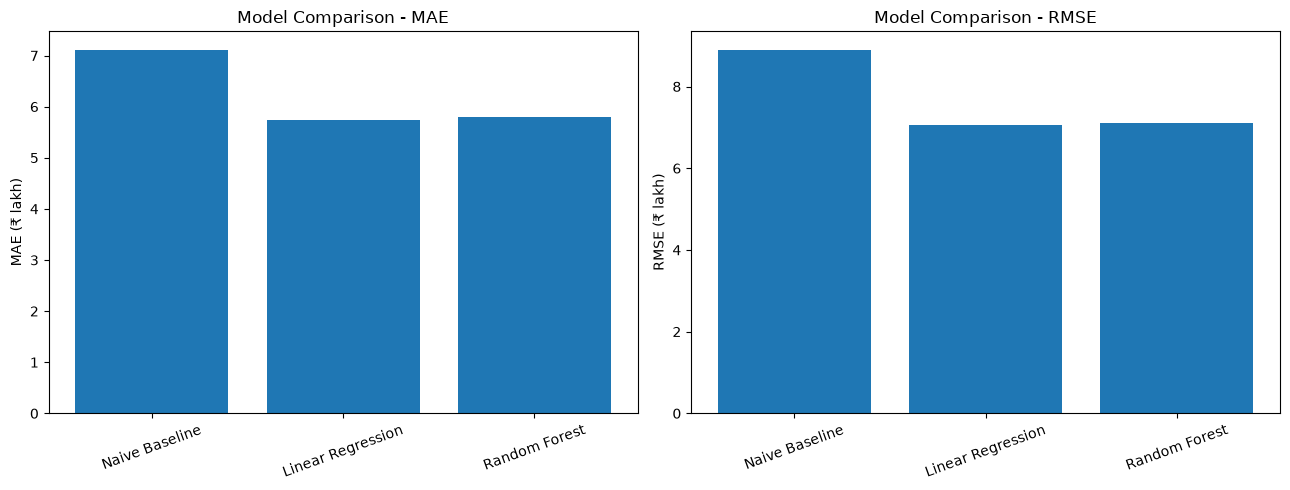

In [8]:

import matplotlib.pyplot as plt
import numpy as np

# Compare model errors in lakh rupees for easier interpretation
models = ["Naive Baseline", "Linear Regression", "Random Forest"]
mae_values = np.array([baseline_mae, linear_mae, rf_mae]) / 100000
rmse_values = np.array([baseline_rmse, linear_rmse, rf_rmse]) / 100000

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# MAE comparison
axes[0].bar(models, mae_values)
axes[0].set_title("Model Comparison - MAE")
axes[0].set_ylabel("MAE (₹ lakh)")
axes[0].tick_params(axis="x", rotation=20)

# RMSE comparison
axes[1].bar(models, rmse_values)
axes[1].set_title("Model Comparison - RMSE")
axes[1].set_ylabel("RMSE (₹ lakh)")
axes[1].tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.show()


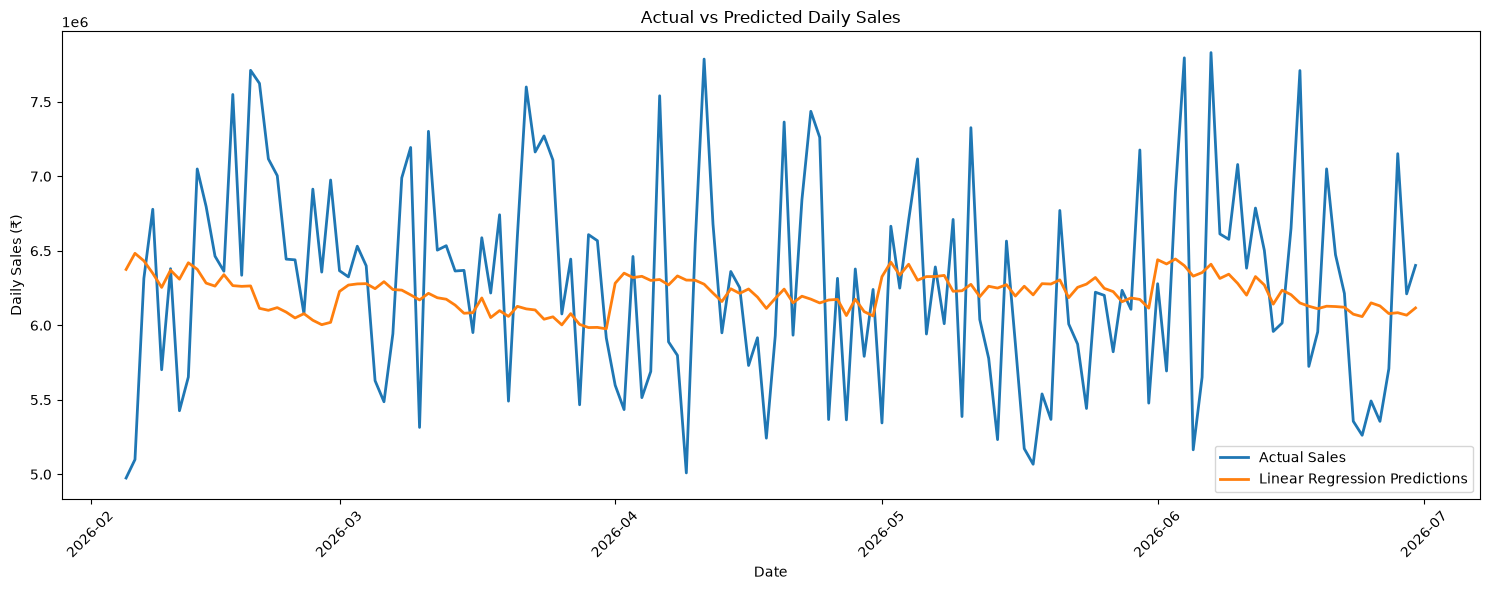

In [9]:

# Compare actual daily sales with Linear Regression predictions
plt.figure(figsize=(15, 6))

plt.plot(
    test_df["Order_Date"],
    y_test,
    label="Actual Sales",
    linewidth=2
)

plt.plot(
    test_df["Order_Date"],
    y_pred_linear,
    label="Linear Regression Predictions",
    linewidth=2
)

plt.title("Actual vs Predicted Daily Sales")
plt.xlabel("Date")
plt.ylabel("Daily Sales (₹)")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


## Analyze prediction errors

In [10]:

# Create a dataframe to compare actual and predicted sales
prediction_results = pd.DataFrame({
    "Order_Date": test_df["Order_Date"].values,
    "Actual_Sales": y_test.values,
    "Linear_Predicted": y_pred_linear,
    "Random_Forest_Predicted": y_pred_rf
})

# Calculate prediction errors (positive = overprediction)
prediction_results["Linear_Error"] = (
    prediction_results["Linear_Predicted"]
    - prediction_results["Actual_Sales"]
)

prediction_results["RF_Error"] = (
    prediction_results["Random_Forest_Predicted"]
    - prediction_results["Actual_Sales"]
)

# Summarize errors and their direction
error_summary = pd.DataFrame({
    "Model": ["Linear Regression", "Random Forest"],
    "Mean_Error": [
        prediction_results["Linear_Error"].mean(),
        prediction_results["RF_Error"].mean()
    ],
    "Mean_Absolute_Error": [
        prediction_results["Linear_Error"].abs().mean(),
        prediction_results["RF_Error"].abs().mean()
    ],
    "Maximum_Absolute_Error": [
        prediction_results["Linear_Error"].abs().max(),
        prediction_results["RF_Error"].abs().max()
    ]
})

display(error_summary.round(2))


,Model,Mean_Error,Mean_Absolute_Error,Maximum_Absolute_Error
0,Linear Regression,-73787.34,574012.64,1560007.10
1,Random Forest,-60761.40,579183.15,1550734.05


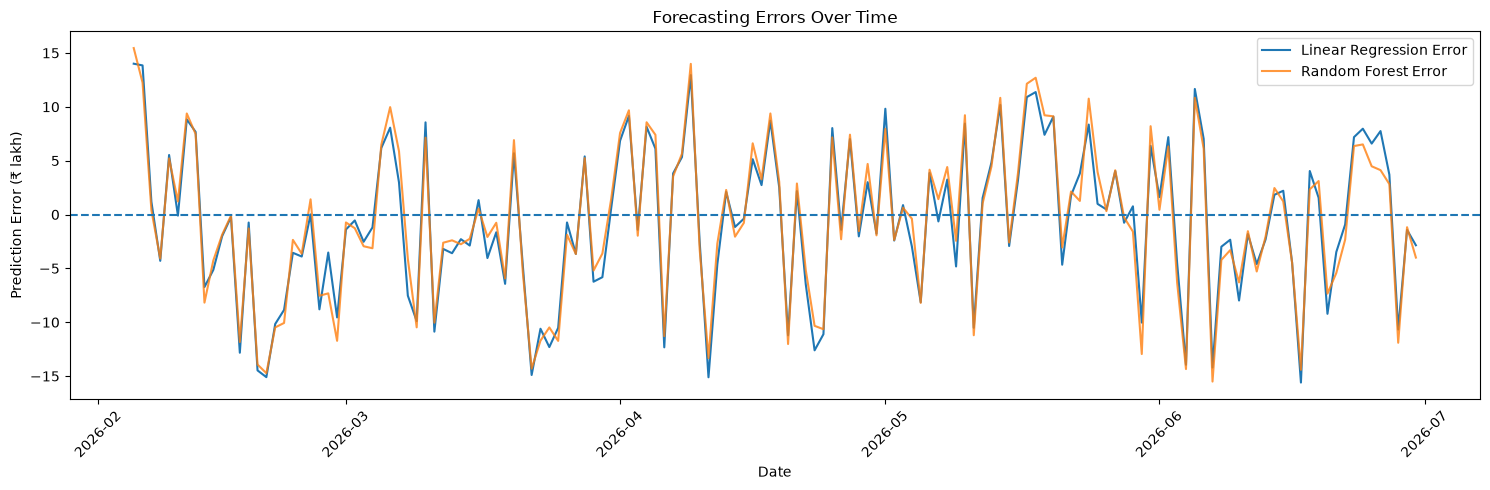

In [11]:

# Plot prediction errors over time
plt.figure(figsize=(15, 5))

plt.plot(
    prediction_results["Order_Date"],
    prediction_results["Linear_Error"] / 100000,
    label="Linear Regression Error"
)

plt.plot(
    prediction_results["Order_Date"],
    prediction_results["RF_Error"] / 100000,
    label="Random Forest Error",
    alpha=0.8
)

# Zero line means prediction exactly matched actual sales
plt.axhline(y=0, linestyle="--")

plt.title("Forecasting Errors Over Time")
plt.xlabel("Date")
plt.ylabel("Prediction Error (₹ lakh)")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


## Tune Random Forest

In [12]:

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd

# Try three Random Forest configurations
rf_configs = [
    {"n_estimators": 200, "max_depth": 6, "min_samples_leaf": 5},
    {"n_estimators": 300, "max_depth": 10, "min_samples_leaf": 3},
    {"n_estimators": 300, "max_depth": 15, "min_samples_leaf": 2},
]

tuning_results = []

for config in rf_configs:
    # Create and train the model
    model = RandomForestRegressor(
        **config,
        random_state=42,
        n_jobs=-1
    )
    model.fit(X_train, y_train)

    # Predict daily sales on the test period
    predictions = model.predict(X_test)

    # Evaluate prediction errors
    mae = mean_absolute_error(y_test, predictions)
    rmse = np.sqrt(mean_squared_error(y_test, predictions))

    tuning_results.append({
        **config,
        "MAE": mae,
        "RMSE": rmse
    })

# Include Linear Regression as our benchmark
tuning_results.append({
    "n_estimators": "-",
    "max_depth": "-",
    "min_samples_leaf": "-",
    "MAE": linear_mae,
    "RMSE": linear_rmse,
    "Model": "Linear Regression"
})

tuning_df = pd.DataFrame(tuning_results)
display(tuning_df.round(2))


,n_estimators,max_depth,min_samples_leaf,MAE,RMSE,Model
0,200,6,5,577668.70,710252.70,NaN
1,300,10,3,578405.53,710599.23,NaN
2,300,15,2,578288.97,710869.96,NaN
3,-,-,-,574012.64,705210.54,Linear Regression


## Save the best model's predictions

In [13]:

from pathlib import Path

# Prepare the forecasting results using the current best model
forecast_results = pd.DataFrame({
    "Order_Date": test_df["Order_Date"].values,
    "Actual_Sales": y_test.values,
    "Predicted_Sales": y_pred_linear
})

# Calculate absolute prediction error for each date
forecast_results["Absolute_Error"] = (
    forecast_results["Actual_Sales"]
    - forecast_results["Predicted_Sales"]
).abs()

# Create the output directory if it does not exist
output_dir = Path("../outputs")
output_dir.mkdir(parents=True, exist_ok=True)

# Export results for reporting and dashboard use
forecast_results.to_csv(
    output_dir / "sales_forecast_test_results.csv",
    index=False
)

print("Forecast results saved successfully.")
print(f"Records exported: {len(forecast_results)}")
display(forecast_results.head())


Forecast results saved successfully.
Records exported: 146


,Order_Date,Actual_Sales,Predicted_Sales,Absolute_Error
0,2026-02-05,4974801.14,6.374902e+06,1.400101e+06
1,2026-02-06,5098793.94,6.482977e+06,1.384183e+06
2,2026-02-07,6314786.25,6.432585e+06,1.177986e+05
3,2026-02-08,6778808.41,6.348852e+06,4.299566e+05
4,2026-02-09,5701629.93,6.254208e+06,5.525780e+05


## Create the model evaluation summary

In [14]:

# Combine all tested models into one evaluation table
final_model_comparison = pd.DataFrame({
    "Model": [
        "Naive Baseline",
        "Linear Regression",
        "Random Forest (Original)",
        "Random Forest (Depth 6)",
        "Random Forest (Depth 10)",
        "Random Forest (Depth 15)"
    ],
    "MAE": [
        baseline_mae,
        linear_mae,
        rf_mae,
        tuning_results[0]["MAE"],
        tuning_results[1]["MAE"],
        tuning_results[2]["MAE"]
    ],
    "RMSE": [
        baseline_rmse,
        linear_rmse,
        rf_rmse,
        tuning_results[0]["RMSE"],
        tuning_results[1]["RMSE"],
        tuning_results[2]["RMSE"]
    ]
})

# Rank models by MAE, then RMSE
final_model_comparison = final_model_comparison.sort_values(
    ["MAE", "RMSE"]
).reset_index(drop=True)

display(final_model_comparison.round(2))

# Save the comparison for reporting and dashboard use
from pathlib import Path

output_dir = Path("../outputs")
output_dir.mkdir(parents=True, exist_ok=True)

final_model_comparison.to_csv(
    output_dir / "sales_model_comparison.csv",
    index=False
)

print("Model comparison saved to outputs/sales_model_comparison.csv")


,Model,MAE,RMSE
0,Linear Regression,574012.64,705210.54
1,Random Forest (Depth 6),577668.70,710252.70
2,Random Forest (Depth 15),578288.97,710869.96
3,Random Forest (Depth 10),578405.53,710599.23
4,Random Forest (Original),579183.15,710904.23
5,Naive Baseline,711757.66,890562.24


Model comparison saved to outputs/sales_model_comparison.csv


## Analyze Linear Regression coefficients

,Feature,Coefficient,Absolute_Coefficient
0,Day_Of_Month,-9601.39,9601.39
1,Month,-5922.68,5922.68
2,Day_Of_Week,-2875.26,2875.26
3,Quarter,-1848.59,1848.59
4,Is_Weekend,-521.49,521.49
5,Rolling_Mean_30,-0.35,0.35
6,Sales_Lag_7,-0.05,0.05
7,Sales_Lag_1,-0.03,0.03
8,Rolling_Mean_7,-0.02,0.02
9,Sales_Lag_30,0.01,0.01


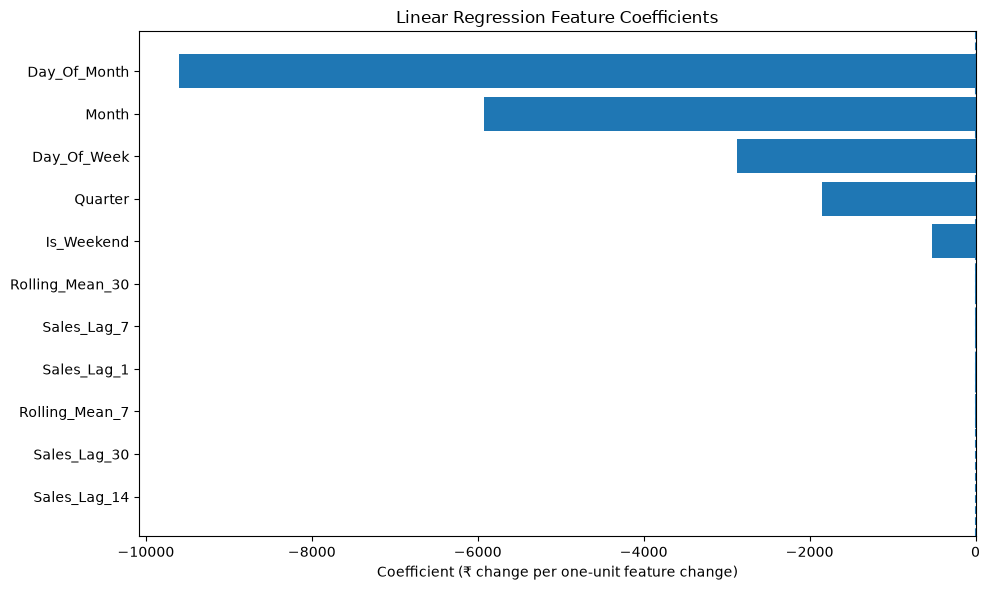

In [15]:

# Examine the influence of each feature in Linear Regression
feature_analysis = pd.DataFrame({
    "Feature": feature_columns,
    "Coefficient": linear_model.coef_
})

# Absolute coefficient shows magnitude, not statistical importance
feature_analysis["Absolute_Coefficient"] = (
    feature_analysis["Coefficient"].abs()
)

feature_analysis = feature_analysis.sort_values(
    "Absolute_Coefficient",
    ascending=False
).reset_index(drop=True)

display(feature_analysis.round(2))

# Visualize coefficients
plt.figure(figsize=(10, 6))
plt.barh(
    feature_analysis["Feature"],
    feature_analysis["Coefficient"]
)
plt.axvline(x=0, linestyle="--")
plt.title("Linear Regression Feature Coefficients")
plt.xlabel("Coefficient (₹ change per one-unit feature change)")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()


,Feature,Importance_MAE,Importance_Std
0,Month,1839.49,813.37
1,Sales_Lag_7,1572.31,1851.01
2,Sales_Lag_14,360.91,608.23
3,Quarter,275.92,102.22
4,Day_Of_Week,160.32,366.48
5,Is_Weekend,-7.86,16.74
6,Sales_Lag_30,-321.46,1025.08
7,Day_Of_Month,-401.50,5831.04
8,Rolling_Mean_7,-1804.46,625.88
9,Sales_Lag_1,-3081.02,1461.79


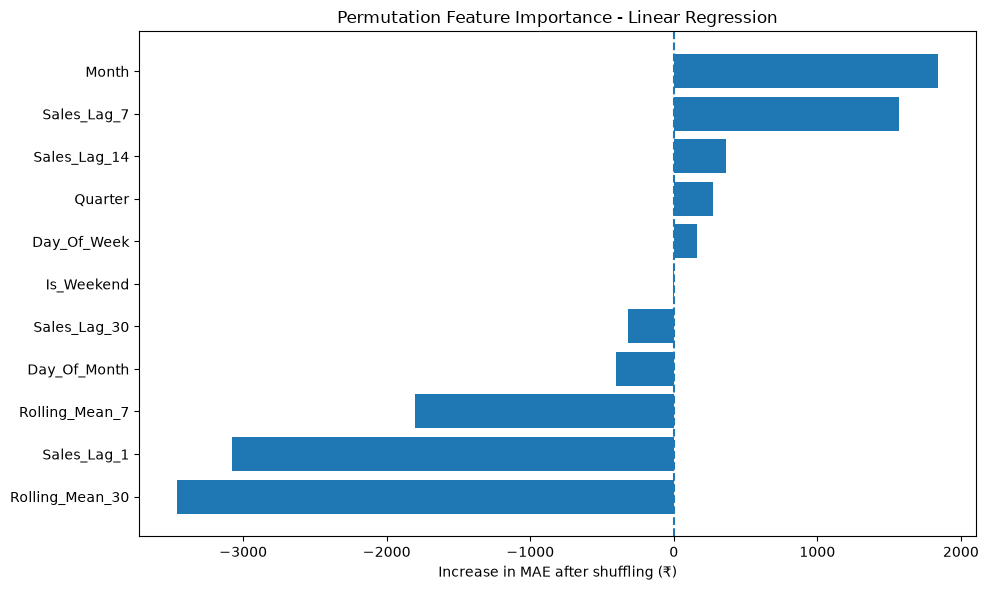

In [16]:

from sklearn.inspection import permutation_importance

# Measure how much model performance worsens when each feature is shuffled
perm_result = permutation_importance(
    linear_model,
    X_test,
    y_test,
    scoring="neg_mean_absolute_error",
    n_repeats=10,
    random_state=42,
    n_jobs=-1
)

# Summarize importance by increase in MAE
permutation_df = pd.DataFrame({
    "Feature": feature_columns,
    "Importance_MAE": perm_result.importances_mean,
    "Importance_Std": perm_result.importances_std
}).sort_values(
    "Importance_MAE",
    ascending=False
).reset_index(drop=True)

display(permutation_df.round(2))

# Plot permutation importance
plt.figure(figsize=(10, 6))
plt.barh(
    permutation_df["Feature"],
    permutation_df["Importance_MAE"]
)
plt.axvline(x=0, linestyle="--")
plt.title("Permutation Feature Importance - Linear Regression")
plt.xlabel("Increase in MAE after shuffling (₹)")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()


In [17]:

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd

# Split the existing training period chronologically:
# first 80% for fitting, last 20% for validation
inner_split = int(len(train_df) * 0.80)

fit_df = train_df.iloc[:inner_split].copy()
validation_df = train_df.iloc[inner_split:].copy()

X_fit = fit_df[feature_columns]
y_fit = fit_df["Daily_Sales"]

X_val = validation_df[feature_columns]
y_val = validation_df["Daily_Sales"]

print("Fitting period:", fit_df["Order_Date"].min().date(),
      "to", fit_df["Order_Date"].max().date())
print("Validation period:", validation_df["Order_Date"].min().date(),
      "to", validation_df["Order_Date"].max().date())

# Train Linear Regression
lr_validation_model = LinearRegression()
lr_validation_model.fit(X_fit, y_fit)
lr_val_pred = lr_validation_model.predict(X_val)

# Train Random Forest using the original configuration
rf_validation_model = RandomForestRegressor(
    n_estimators=200,
    max_depth=10,
    min_samples_leaf=3,
    random_state=42,
    n_jobs=-1
)
rf_validation_model.fit(X_fit, y_fit)
rf_val_pred = rf_validation_model.predict(X_val)

# Compare validation performance
validation_results = pd.DataFrame({
    "Model": ["Naive Baseline", "Linear Regression", "Random Forest"],
    "MAE": [
        mean_absolute_error(y_val, X_val["Sales_Lag_1"]),
        mean_absolute_error(y_val, lr_val_pred),
        mean_absolute_error(y_val, rf_val_pred)
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(y_val, X_val["Sales_Lag_1"])),
        np.sqrt(mean_squared_error(y_val, lr_val_pred)),
        np.sqrt(mean_squared_error(y_val, rf_val_pred))
    ]
})

display(validation_results.round(2))


Fitting period: 2024-07-01 to 2025-10-10
Validation period: 2025-10-11 to 2026-02-04


,Model,MAE,RMSE
0,Naive Baseline,949138.31,1127903.46
1,Linear Regression,687725.63,828807.55
2,Random Forest,679346.85,822307.13


In [18]:

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd

# Train Linear Regression on the full training period
final_lr = LinearRegression()
final_lr.fit(X_train, y_train)
final_lr_pred = final_lr.predict(X_test)

# Train Random Forest on the same training period
final_rf = RandomForestRegressor(
    n_estimators=200,
    max_depth=10,
    min_samples_leaf=3,
    random_state=42,
    n_jobs=-1
)
final_rf.fit(X_train, y_train)
final_rf_pred = final_rf.predict(X_test)

# Compare both models on the untouched test period
final_test_comparison = pd.DataFrame({
    "Model": ["Linear Regression", "Random Forest"],
    "MAE": [
        mean_absolute_error(y_test, final_lr_pred),
        mean_absolute_error(y_test, final_rf_pred)
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(y_test, final_lr_pred)),
        np.sqrt(mean_squared_error(y_test, final_rf_pred))
    ]
})

display(final_test_comparison.round(2))


,Model,MAE,RMSE
0,Linear Regression,574012.64,705210.54
1,Random Forest,579183.15,710904.23


In [19]:

from pathlib import Path
import pandas as pd
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Save final test-period predictions
final_forecast_results = pd.DataFrame({
    "Order_Date": test_df["Order_Date"].values,
    "Actual_Sales": y_test.values,
    "Predicted_Sales": final_lr_pred
})

final_forecast_results["Absolute_Error"] = (
    final_forecast_results["Actual_Sales"]
    - final_forecast_results["Predicted_Sales"]
).abs()

# Calculate final evaluation metrics
final_metrics = pd.DataFrame({
    "Metric": ["MAE", "RMSE"],
    "Value": [
        mean_absolute_error(y_test, final_lr_pred),
        np.sqrt(mean_squared_error(y_test, final_lr_pred))
    ]
})

# Ensure output folder exists
output_dir = Path("../outputs")
output_dir.mkdir(parents=True, exist_ok=True)

# Export predictions and metrics
final_forecast_results.to_csv(
    output_dir / "sales_forecast_test_results.csv",
    index=False
)

final_metrics.to_csv(
    output_dir / "sales_forecast_metrics.csv",
    index=False
)

print("Final forecasting outputs saved successfully.")
print("Prediction records:", len(final_forecast_results))
display(final_metrics)
display(final_forecast_results.head())


Final forecasting outputs saved successfully.
Prediction records: 146


,Metric,Value
0,MAE,574012.636155
1,RMSE,705210.537932


,Order_Date,Actual_Sales,Predicted_Sales,Absolute_Error
0,2026-02-05,4974801.14,6.374902e+06,1.400101e+06
1,2026-02-06,5098793.94,6.482977e+06,1.384183e+06
2,2026-02-07,6314786.25,6.432585e+06,1.177986e+05
3,2026-02-08,6778808.41,6.348852e+06,4.299566e+05
4,2026-02-09,5701629.93,6.254208e+06,5.525780e+05


In [20]:

import joblib
from pathlib import Path

# Create a folder for saved machine learning models
model_dir = Path("../models")
model_dir.mkdir(parents=True, exist_ok=True)

# Save the final trained Linear Regression model
model_path = model_dir / "sales_forecasting_model.pkl"
joblib.dump(final_lr, model_path)

# Save the feature names and their required order
feature_path = model_dir / "forecast_features.pkl"
joblib.dump(feature_columns, feature_path)

print("Model saved successfully!")
print(f"Model path: {model_path}")
print(f"Feature list saved: {feature_path}")


Model saved successfully!
Model path: ..\models\sales_forecasting_model.pkl
Feature list saved: ..\models\forecast_features.pkl


In [21]:

from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd

# Predict each test day's sales using the same weekday
# from the previous week.
y_pred_weekly = X_test["Sales_Lag_7"]

weekly_mae = mean_absolute_error(y_test, y_pred_weekly)
weekly_rmse = np.sqrt(mean_squared_error(y_test, y_pred_weekly))

# Compare all baselines and ML models
baseline_comparison = pd.DataFrame({
    "Model": [
        "Previous-Day Baseline",
        "Previous-Weekday Baseline",
        "Linear Regression",
        "Random Forest"
    ],
    "MAE": [
        baseline_mae,
        weekly_mae,
        linear_mae,
        rf_mae
    ],
    "RMSE": [
        baseline_rmse,
        weekly_rmse,
        linear_rmse,
        rf_rmse
    ]
})

display(baseline_comparison.round(2))


,Model,MAE,RMSE
0,Previous-Day Baseline,711757.66,890562.24
1,Previous-Weekday Baseline,814937.78,998930.59
2,Linear Regression,574012.64,705210.54
3,Random Forest,579183.15,710904.23


In [22]:

# Create a copy of the existing feature dataframe
experiment_df = forecast_df.copy()

# Use only previous days to calculate the rolling median
experiment_df["Rolling_Median_7"] = (
    experiment_df["Daily_Sales"]
    .shift(1)
    .rolling(window=7)
    .median()
)

# Add the new feature to the existing feature list
experiment_features = feature_columns + ["Rolling_Median_7"]

# Remove rows with missing values in the new feature set
experiment_model_df = experiment_df.dropna(
    subset=experiment_features + ["Daily_Sales"]
).copy()

# Preserve chronological order
experiment_model_df = experiment_model_df.sort_values(
    "Order_Date"
).reset_index(drop=True)

# Recreate the chronological 80/20 split
experiment_split = int(len(experiment_model_df) * 0.80)

experiment_train = experiment_model_df.iloc[:experiment_split]
experiment_test = experiment_model_df.iloc[experiment_split:]

X_train_exp = experiment_train[experiment_features]
y_train_exp = experiment_train["Daily_Sales"]

X_test_exp = experiment_test[experiment_features]
y_test_exp = experiment_test["Daily_Sales"]

print("Training records:", len(experiment_train))
print("Test records:", len(experiment_test))
print("New feature added: Rolling_Median_7")


Training records: 584
Test records: 146
New feature added: Rolling_Median_7


In [23]:

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd

# Train Linear Regression with the new rolling median feature
lr_median = LinearRegression()
lr_median.fit(X_train_exp, y_train_exp)
lr_median_pred = lr_median.predict(X_test_exp)

# Train Random Forest with the same feature set
rf_median = RandomForestRegressor(
    n_estimators=200,
    max_depth=10,
    min_samples_leaf=3,
    random_state=42,
    n_jobs=-1
)
rf_median.fit(X_train_exp, y_train_exp)
rf_median_pred = rf_median.predict(X_test_exp)

# Evaluate the new models
median_results = pd.DataFrame({
    "Model": ["Linear Regression + Median", "Random Forest + Median"],
    "MAE": [
        mean_absolute_error(y_test_exp, lr_median_pred),
        mean_absolute_error(y_test_exp, rf_median_pred)
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(y_test_exp, lr_median_pred)),
        np.sqrt(mean_squared_error(y_test_exp, rf_median_pred))
    ]
})

display(median_results.round(2))


,Model,MAE,RMSE
0,Linear Regression + Median,573499.39,702193.07
1,Random Forest + Median,578601.99,710173.85


In [24]:

# Calculate baseline predictions on the experiment test period
previous_day_pred = X_test_exp["Sales_Lag_1"]
previous_week_pred = X_test_exp["Sales_Lag_7"]

# Compare baselines and the new ML models on identical test dates
same_period_results = pd.DataFrame({
    "Model": [
        "Previous-Day Baseline",
        "Previous-Weekday Baseline",
        "Linear Regression + Median",
        "Random Forest + Median"
    ],
    "MAE": [
        mean_absolute_error(y_test_exp, previous_day_pred),
        mean_absolute_error(y_test_exp, previous_week_pred),
        mean_absolute_error(y_test_exp, lr_median_pred),
        mean_absolute_error(y_test_exp, rf_median_pred)
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(y_test_exp, previous_day_pred)),
        np.sqrt(mean_squared_error(y_test_exp, previous_week_pred)),
        np.sqrt(mean_squared_error(y_test_exp, lr_median_pred)),
        np.sqrt(mean_squared_error(y_test_exp, rf_median_pred))
    ]
})

display(same_period_results.round(2))


,Model,MAE,RMSE
0,Previous-Day Baseline,711757.66,890562.24
1,Previous-Weekday Baseline,814937.78,998930.59
2,Linear Regression + Median,573499.39,702193.07
3,Random Forest + Median,578601.99,710173.85


Linear Regression + Rolling Median
----------------------------------------
Mean Error: ₹-74,466.81
Mean Absolute Error: ₹573,499.39
Maximum Absolute Error: ₹1,568,449.97


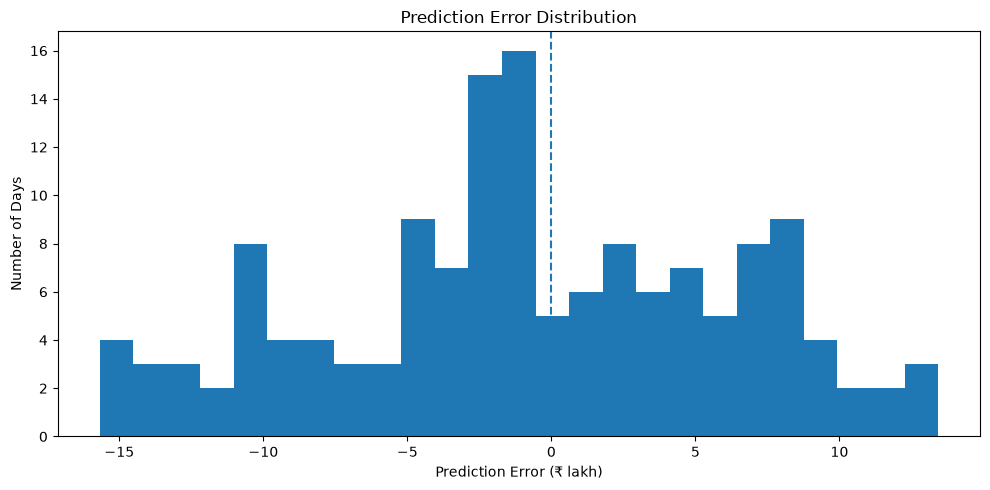

In [25]:

# Calculate signed prediction errors
# Positive error = overprediction; negative error = underprediction
median_errors = lr_median_pred - y_test_exp.to_numpy()

# Summarize the error distribution
print("Linear Regression + Rolling Median")
print("-" * 40)
print(f"Mean Error: ₹{median_errors.mean():,.2f}")
print(f"Mean Absolute Error: ₹{np.abs(median_errors).mean():,.2f}")
print(f"Maximum Absolute Error: ₹{np.abs(median_errors).max():,.2f}")

# Visualize the error distribution
plt.figure(figsize=(10, 5))
plt.hist(median_errors / 100000, bins=25)
plt.axvline(x=0, linestyle="--")
plt.title("Prediction Error Distribution")
plt.xlabel("Prediction Error (₹ lakh)")
plt.ylabel("Number of Days")
plt.tight_layout()
plt.show()


In [26]:

# Create a detailed error-analysis table
error_analysis = pd.DataFrame({
    "Order_Date": experiment_test["Order_Date"].values,
    "Actual_Sales": y_test_exp.values,
    "Predicted_Sales": lr_median_pred
})

# Calculate signed and absolute prediction errors
error_analysis["Error"] = (
    error_analysis["Predicted_Sales"]
    - error_analysis["Actual_Sales"]
)

error_analysis["Absolute_Error"] = (
    error_analysis["Error"].abs()
)

# Display the 10 days with the largest prediction errors
worst_days = error_analysis.sort_values(
    "Absolute_Error",
    ascending=False
).head(10)

display(worst_days.round(2))


C:\Users\ganes\AppData\Local\Temp\ipykernel_1812\2470118736.py:24: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(worst_days.round(2))


,Order_Date,Actual_Sales,Predicted_Sales,Error,Absolute_Error
132,2026-06-17,7709804.59,6141354.62,-1568449.97,1568449.97
45,2026-03-22,7599699.42,6090335.25,-1509364.17,1509364.17
15,2026-02-20,7623590.26,6133946.70,-1489643.56,1489643.56
65,2026-04-11,7786847.15,6305380.91,-1481466.24,1481466.24
14,2026-02-19,7711248.13,6288995.78,-1422252.35,1422252.35
119,2026-06-04,7795157.07,6407006.80,-1388150.27,1388150.27
0,2026-02-05,4974801.14,6317194.87,1342393.73,1342393.73
122,2026-06-07,7830331.42,6488885.30,-1341446.12,1341446.12
63,2026-04-09,5009063.64,6333889.55,1324825.91,1324825.91
1,2026-02-06,5098793.94,6410916.50,1312122.56,1312122.56


In [27]:

# Load the original sales data
sales_raw = pd.read_csv("../data/sales.csv")
sales_raw["Order_Date"] = pd.to_datetime(sales_raw["Order_Date"])

# Keep only delivered orders
delivered_raw = sales_raw[
    sales_raw["Order_Status"] == "Delivered"
].copy()

# Calculate daily order count and recorded sales
daily_order_summary = (
    delivered_raw.groupby("Order_Date")
    .agg(
        Delivered_Orders=("Order_ID", "nunique"),
        Daily_Sales=("Total_Amount", "sum")
    )
    .reset_index()
)

# Attach order counts to the worst prediction days
worst_day_details = worst_days.merge(
    daily_order_summary,
    on="Order_Date",
    how="left",
    suffixes=("_Model", "_Source")
)

# Calculate the average delivered order count across the full dataset
average_daily_orders = daily_order_summary["Delivered_Orders"].mean()

worst_day_details["Orders_vs_Average"] = (
    worst_day_details["Delivered_Orders"] - average_daily_orders
)

display(
    worst_day_details[
        [
            "Order_Date",
            "Actual_Sales",
            "Predicted_Sales",
            "Error",
            "Delivered_Orders",
            "Orders_vs_Average"
        ]
    ].round(2)
)

print(f"Average daily delivered orders: {average_daily_orders:.2f}")


C:\Users\ganes\AppData\Local\Temp\ipykernel_1812\1516514430.py:45: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ].round(2)


,Order_Date,Actual_Sales,Predicted_Sales,Error,Delivered_Orders,Orders_vs_Average
0,2026-06-17,7709804.59,6141354.62,-1568449.97,267,3.66
1,2026-03-22,7599699.42,6090335.25,-1509364.17,285,21.66
2,2026-02-20,7623590.26,6133946.70,-1489643.56,257,-6.34
3,2026-04-11,7786847.15,6305380.91,-1481466.24,307,43.66
4,2026-02-19,7711248.13,6288995.78,-1422252.35,280,16.66
5,2026-06-04,7795157.07,6407006.80,-1388150.27,270,6.66
6,2026-02-05,4974801.14,6317194.87,1342393.73,270,6.66
7,2026-06-07,7830331.42,6488885.30,-1341446.12,272,8.66
8,2026-04-09,5009063.64,6333889.55,1324825.91,273,9.66
9,2026-02-06,5098793.94,6410916.50,1312122.56,264,0.66


Average daily delivered orders: 263.34


In [28]:

# Calculate average recorded sales amount per delivered order
daily_order_summary["Average_Order_Value"] = (
    daily_order_summary["Daily_Sales"]
    / daily_order_summary["Delivered_Orders"]
)

# Show average order value for the 10 worst prediction days
aov_check = worst_days[["Order_Date", "Actual_Sales", "Predicted_Sales", "Error"]].merge(
    daily_order_summary[
        ["Order_Date", "Delivered_Orders", "Average_Order_Value"]
    ],
    on="Order_Date",
    how="left"
)

display(aov_check.round(2))


C:\Users\ganes\AppData\Local\Temp\ipykernel_1812\745218928.py:16: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(aov_check.round(2))


,Order_Date,Actual_Sales,Predicted_Sales,Error,Delivered_Orders,Average_Order_Value
0,2026-06-17,7709804.59,6141354.62,-1568449.97,267,28875.67
1,2026-03-22,7599699.42,6090335.25,-1509364.17,285,26665.61
2,2026-02-20,7623590.26,6133946.70,-1489643.56,257,29663.78
3,2026-04-11,7786847.15,6305380.91,-1481466.24,307,25364.32
4,2026-02-19,7711248.13,6288995.78,-1422252.35,280,27540.17
5,2026-06-04,7795157.07,6407006.80,-1388150.27,270,28870.95
6,2026-02-05,4974801.14,6317194.87,1342393.73,270,18425.19
7,2026-06-07,7830331.42,6488885.30,-1341446.12,272,28787.98
8,2026-04-09,5009063.64,6333889.55,1324825.91,273,18348.22
9,2026-02-06,5098793.94,6410916.50,1312122.56,264,19313.61


In [29]:

# Calculate daily sales and delivered order counts
daily_order_summary["Average_Order_Value"] = (
    daily_order_summary["Daily_Sales"]
    / daily_order_summary["Delivered_Orders"]
)

# Compare average order value on the worst prediction days
worst_day_aov = worst_day_details[
    ["Order_Date", "Actual_Sales", "Predicted_Sales",
     "Delivered_Orders", "Error"]
].merge(
    daily_order_summary[
        ["Order_Date", "Average_Order_Value"]
    ],
    on="Order_Date",
    how="left"
)

# Calculate overall average order value across delivered orders
overall_aov = (
    delivered_raw["Total_Amount"].sum()
    / delivered_raw["Order_ID"].nunique()
)

worst_day_aov["AOV_vs_Overall"] = (
    worst_day_aov["Average_Order_Value"] - overall_aov
)

display(worst_day_aov.round(2))

print(f"Overall average recorded amount per delivered order: ₹{overall_aov:,.2f}")


C:\Users\ganes\AppData\Local\Temp\ipykernel_1812\1477018908.py:29: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(worst_day_aov.round(2))


,Order_Date,Actual_Sales,Predicted_Sales,Delivered_Orders,Error,Average_Order_Value,AOV_vs_Overall
0,2026-06-17,7709804.59,6141354.62,267,-1568449.97,28875.67,5184.31
1,2026-03-22,7599699.42,6090335.25,285,-1509364.17,26665.61,2974.25
2,2026-02-20,7623590.26,6133946.70,257,-1489643.56,29663.78,5972.41
3,2026-04-11,7786847.15,6305380.91,307,-1481466.24,25364.32,1672.96
4,2026-02-19,7711248.13,6288995.78,280,-1422252.35,27540.17,3848.81
5,2026-06-04,7795157.07,6407006.80,270,-1388150.27,28870.95,5179.59
6,2026-02-05,4974801.14,6317194.87,270,1342393.73,18425.19,-5266.18
7,2026-06-07,7830331.42,6488885.30,272,-1341446.12,28787.98,5096.62
8,2026-04-09,5009063.64,6333889.55,273,1324825.91,18348.22,-5343.15
9,2026-02-06,5098793.94,6410916.50,264,1312122.56,19313.61,-4377.75


Overall average recorded amount per delivered order: ₹23,691.37


In [31]:
# Create a copy of the daily order summary
daily_components = daily_order_summary.copy()

# Calculate Average Order Value (AOV) for each day
daily_components["Average_Order_Value"] = (
    daily_components["Daily_Sales"]
    / daily_components["Delivered_Orders"]
)

# Display the first five rows
display(daily_components.head())

,Order_Date,Delivered_Orders,Daily_Sales,Average_Order_Value
0,2024-06-01,241,6704620.83,27820.003444
1,2024-06-02,265,6347543.90,23952.995849
2,2024-06-03,244,5984976.05,24528.590369
3,2024-06-04,250,5847043.56,23388.174240
4,2024-06-05,289,5827407.17,20164.038651


In [32]:

# Summarize daily sales, delivered orders and average order value
component_summary = daily_components[
    ["Daily_Sales", "Delivered_Orders", "Average_Order_Value"]
].agg(["mean", "std", "min", "max"]).T

# Compare variability relative to each variable's mean
component_summary["CV_Percent"] = (
    component_summary["std"] / component_summary["mean"] * 100
)

display(component_summary.round(2))


,mean,std,min,max,CV_Percent
Daily_Sales,6238903.10,729329.15,4300694.45,8634094.30,11.69
Delivered_Orders,263.34,16.26,219.00,323.00,6.17
Average_Order_Value,23685.56,2295.91,17639.08,31687.26,9.69


In [33]:
# Check the date range and available columns
print("Daily components shape:", daily_components.shape)

print(
    "Date range:",
    daily_components["Order_Date"].min(),
    "to",
    daily_components["Order_Date"].max()
)

display(daily_components.head())

Daily components shape: (760, 4)
Date range: 2024-06-01 00:00:00 to 2026-06-30 00:00:00


,Order_Date,Delivered_Orders,Daily_Sales,Average_Order_Value
0,2024-06-01,241,6704620.83,27820.003444
1,2024-06-02,265,6347543.90,23952.995849
2,2024-06-03,244,5984976.05,24528.590369
3,2024-06-04,250,5847043.56,23388.174240
4,2024-06-05,289,5827407.17,20164.038651


In [34]:
import pandas as pd
import numpy as np

# Create a copy of the daily components
component_df = daily_components.copy()

# Ensure dates are sorted chronologically
component_df = component_df.sort_values("Order_Date").reset_index(drop=True)

# Create calendar features
component_df["Day_Of_Week"] = component_df["Order_Date"].dt.dayofweek
component_df["Day_Of_Month"] = component_df["Order_Date"].dt.day
component_df["Month"] = component_df["Order_Date"].dt.month
component_df["Quarter"] = component_df["Order_Date"].dt.quarter
component_df["Is_Weekend"] = (
    component_df["Day_Of_Week"] >= 5
).astype(int)

# Create lag features for delivered orders
for lag in [1, 7, 14, 30]:
    component_df[f"Orders_Lag_{lag}"] = (
        component_df["Delivered_Orders"].shift(lag)
    )

# Create lag features for average order value
for lag in [1, 7, 14, 30]:
    component_df[f"AOV_Lag_{lag}"] = (
        component_df["Average_Order_Value"].shift(lag)
    )

# Create rolling averages using past days only
component_df["Orders_Rolling_Mean_7"] = (
    component_df["Delivered_Orders"].shift(1).rolling(7).mean()
)

component_df["AOV_Rolling_Mean_7"] = (
    component_df["Average_Order_Value"].shift(1).rolling(7).mean()
)

# Remove rows where lag or rolling features are missing
component_model_df = component_df.dropna().copy()

print("Original rows:", len(component_df))
print("Rows available for modeling:", len(component_model_df))
print("First modeling date:", component_model_df["Order_Date"].min())
print("Last modeling date:", component_model_df["Order_Date"].max())

display(component_model_df.head())

Original rows: 760
Rows available for modeling: 730
First modeling date: 2024-07-01 00:00:00
Last modeling date: 2026-06-30 00:00:00


,Order_Date,Delivered_Orders,Daily_Sales,Average_Order_Value,Day_Of_Week,Day_Of_Month,Month,Quarter,Is_Weekend,Orders_Lag_1,Orders_Lag_7,Orders_Lag_14,Orders_Lag_30,AOV_Lag_1,AOV_Lag_7,AOV_Lag_14,AOV_Lag_30,Orders_Rolling_Mean_7,AOV_Rolling_Mean_7
30,2024-07-01,257,5723422.00,22270.124514,0,1,7,3,0,281.0,283.0,239.0,241.0,25832.527687,22591.088516,26372.193515,27820.003444,272.000000,23825.677391
31,2024-07-02,247,5464947.37,22125.292996,1,2,7,3,0,257.0,247.0,247.0,265.0,22270.124514,21733.227935,22579.783644,23952.995849,268.285714,23779.825391
32,2024-07-03,235,6659981.88,28340.348426,2,3,7,3,0,247.0,274.0,300.0,244.0,22125.292996,22334.234088,26144.789333,24528.590369,268.285714,23835.834685
33,2024-07-04,323,8538895.37,26436.208576,3,4,7,3,0,235.0,289.0,269.0,250.0,28340.348426,25581.945433,23422.494907,23388.174240,262.714286,24693.851019
34,2024-07-05,274,6266653.59,22870.998504,4,5,7,3,0,323.0,258.0,291.0,289.0,26436.208576,24993.358411,25154.736048,20164.038651,267.571429,24815.888611


## Train and evaluate the component models

In [37]:
# Combine predicted orders and predicted AOV
predicted_component_sales = predicted_orders * predicted_aov

# Actual sales for the test period
actual_component_sales = test_data["Daily_Sales"].to_numpy()

# Create a writable copy of the previous-day baseline
previous_day_sales = test_data["Daily_Sales"].shift(1).to_numpy().copy()

# Fill the first test day's baseline using the last training day's sales
previous_day_sales[0] = train_data["Daily_Sales"].iloc[-1]

# Evaluate both approaches
results = pd.DataFrame({
    "Model": [
        "Previous-Day Baseline",
        "Orders × AOV Linear Regression"
    ],
    "MAE": [
        mean_absolute_error(actual_component_sales, previous_day_sales),
        mean_absolute_error(actual_component_sales, predicted_component_sales)
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(actual_component_sales, previous_day_sales)),
        np.sqrt(mean_squared_error(actual_component_sales, predicted_component_sales))
    ]
})

print("Training dates:",
      train_data["Order_Date"].min().date(),
      "to", train_data["Order_Date"].max().date())

print("Testing dates:",
      test_data["Order_Date"].min().date(),
      "to", test_data["Order_Date"].max().date())

display(results.round(2))

Training dates: 2024-07-01 to 2026-02-04
Testing dates: 2026-02-05 to 2026-06-30


,Model,MAE,RMSE
0,Previous-Day Baseline,711757.66,890562.24
1,Orders × AOV Linear Regression,572762.16,706383.72


In [39]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd

# Align the direct-sales dataset to the component model's dates
direct_test = test_data[["Order_Date", "Daily_Sales"]].merge(
    model_df[["Order_Date"] + feature_columns],
    on="Order_Date",
    how="inner"
).sort_values("Order_Date").reset_index(drop=True)

# Use only dates before the component model's test period for training
direct_train = model_df[
    model_df["Order_Date"] < test_data["Order_Date"].min()
].copy()

# Train the direct-sales Linear Regression model
direct_model = LinearRegression()

direct_model.fit(
    direct_train[feature_columns],
    direct_train["Daily_Sales"]
)

# Predict direct daily sales
direct_predictions = direct_model.predict(
    direct_test[feature_columns]
)

# Align component predictions to the same dates
component_results = test_data[
    ["Order_Date", "Daily_Sales"]
].copy()

component_results["Component_Prediction"] = predicted_component_sales

direct_results = direct_test[
    ["Order_Date", "Daily_Sales"]
].copy()

direct_results["Direct_Prediction"] = direct_predictions

comparison = component_results.merge(
    direct_results[["Order_Date", "Direct_Prediction"]],
    on="Order_Date",
    how="inner"
)

# Evaluate both models on identical dates
actual = comparison["Daily_Sales"]

comparison_metrics = pd.DataFrame({
    "Model": [
        "Direct Sales Linear Regression",
        "Orders × AOV Linear Regression"
    ],
    "MAE": [
        mean_absolute_error(actual, comparison["Direct_Prediction"]),
        mean_absolute_error(actual, comparison["Component_Prediction"])
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(actual, comparison["Direct_Prediction"])),
        np.sqrt(mean_squared_error(actual, comparison["Component_Prediction"]))
    ]
})

print("Shared test dates:",
      comparison["Order_Date"].min().date(),
      "to",
      comparison["Order_Date"].max().date())

print("Shared test days:", len(comparison))

display(comparison_metrics.round(2))

Shared test dates: 2026-02-05 to 2026-06-30
Shared test days: 146


,Model,MAE,RMSE
0,Direct Sales Linear Regression,574012.64,705210.54
1,Orders × AOV Linear Regression,572762.16,706383.72


In [40]:
# Calculate prediction errors on the shared test dates
comparison["Direct_Error"] = (
    comparison["Direct_Prediction"] - comparison["Daily_Sales"]
)

comparison["Direct_Absolute_Error"] = comparison["Direct_Error"].abs()

# Summarize the direct model's errors
error_summary = pd.Series({
    "Mean_Error": comparison["Direct_Error"].mean(),
    "MAE": comparison["Direct_Absolute_Error"].mean(),
    "Maximum_Absolute_Error": comparison["Direct_Absolute_Error"].max(),
    "Underprediction_Days": (comparison["Direct_Error"] < 0).sum(),
    "Overprediction_Days": (comparison["Direct_Error"] > 0).sum()
})

display(error_summary.round(2))

# Inspect the ten days with the largest errors
worst_direct_days = comparison.nlargest(
    10, "Direct_Absolute_Error"
)[[
    "Order_Date",
    "Daily_Sales",
    "Direct_Prediction",
    "Direct_Error",
    "Direct_Absolute_Error"
]]

display(worst_direct_days.round(2))

Mean_Error                 -73787.34
MAE                        574012.64
Maximum_Absolute_Error    1560007.10
Underprediction_Days           81.00
Overprediction_Days            65.00
dtype: float64

C:\Users\ganes\AppData\Local\Temp\ipykernel_1812\2055765376.py:30: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(worst_direct_days.round(2))


,Order_Date,Daily_Sales,Direct_Prediction,Direct_Error,Direct_Absolute_Error
132,2026-06-17,7709804.59,6149797.49,-1560007.10,1560007.10
65,2026-04-11,7786847.15,6275886.07,-1510961.08,1510961.08
15,2026-02-20,7623590.26,6113895.69,-1509694.57,1509694.57
45,2026-03-22,7599699.42,6110070.80,-1489628.62,1489628.62
14,2026-02-19,7711248.13,6264212.52,-1447035.61,1447035.61
122,2026-06-07,7830331.42,6409932.51,-1420398.91,1420398.91
0,2026-02-05,4974801.14,6374901.72,1400100.58,1400100.58
119,2026-06-04,7795157.07,6400452.37,-1394704.70,1394704.70
1,2026-02-06,5098793.94,6482977.36,1384183.42,1384183.42
63,2026-04-09,5009063.64,6303359.69,1294296.05,1294296.05


In [41]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd

# Train Random Forest using the same training data
rf_direct_model = RandomForestRegressor(
    n_estimators=300,
    max_depth=10,
    min_samples_leaf=3,
    random_state=42,
    n_jobs=-1
)

rf_direct_model.fit(
    direct_train[feature_columns],
    direct_train["Daily_Sales"]
)

# Predict sales for the same test dates
rf_direct_predictions = rf_direct_model.predict(
    direct_test[feature_columns]
)

# Compare Random Forest with direct Linear Regression
model_comparison = pd.DataFrame({
    "Model": [
        "Direct Linear Regression",
        "Direct Random Forest"
    ],
    "MAE": [
        mean_absolute_error(
            direct_test["Daily_Sales"],
            direct_predictions
        ),
        mean_absolute_error(
            direct_test["Daily_Sales"],
            rf_direct_predictions
        )
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(
            direct_test["Daily_Sales"],
            direct_predictions
        )),
        np.sqrt(mean_squared_error(
            direct_test["Daily_Sales"],
            rf_direct_predictions
        ))
    ]
})

display(model_comparison.round(2))

,Model,MAE,RMSE
0,Direct Linear Regression,574012.64,705210.54
1,Direct Random Forest,578405.53,710599.23


In [42]:
# Examine Linear Regression coefficients
coefficient_analysis = pd.DataFrame({
    "Feature": feature_columns,
    "Coefficient": direct_model.coef_
})

# Sort by absolute coefficient magnitude
coefficient_analysis["Absolute_Coefficient"] = (
    coefficient_analysis["Coefficient"].abs()
)

coefficient_analysis = coefficient_analysis.sort_values(
    "Absolute_Coefficient",
    ascending=False
)

display(coefficient_analysis.round(2))

,Feature,Coefficient,Absolute_Coefficient
1,Day_Of_Month,-9601.39,9601.39
2,Month,-5922.68,5922.68
0,Day_Of_Week,-2875.26,2875.26
3,Quarter,-1848.59,1848.59
4,Is_Weekend,-521.49,521.49
10,Rolling_Mean_30,-0.35,0.35
6,Sales_Lag_7,-0.05,0.05
5,Sales_Lag_1,-0.03,0.03
9,Rolling_Mean_7,-0.02,0.02
8,Sales_Lag_30,0.01,0.01


In [43]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
import pandas as pd

# Scale features using training data only
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(
    direct_train[feature_columns]
)

X_test_scaled = scaler.transform(
    direct_test[feature_columns]
)

# Train a new Linear Regression model on scaled features
scaled_lr_model = LinearRegression()

scaled_lr_model.fit(
    X_train_scaled,
    direct_train["Daily_Sales"]
)

# Compare standardized coefficients
standardized_coefficients = pd.DataFrame({
    "Feature": feature_columns,
    "Standardized_Coefficient": scaled_lr_model.coef_
})

standardized_coefficients["Absolute_Importance"] = (
    standardized_coefficients["Standardized_Coefficient"].abs()
)

standardized_coefficients = standardized_coefficients.sort_values(
    "Absolute_Importance",
    ascending=False
)

display(standardized_coefficients.round(2))

,Feature,Standardized_Coefficient,Absolute_Importance
1,Day_Of_Month,-85130.08,85130.08
2,Month,-74554.58,74554.58
3,Quarter,52303.21,52303.21
10,Rolling_Mean_30,-39817.67,39817.67
6,Sales_Lag_7,-34563.70,34563.70
0,Day_Of_Week,-21863.72,21863.72
4,Is_Weekend,19827.71,19827.71
5,Sales_Lag_1,-19373.26,19373.26
8,Sales_Lag_30,10530.80,10530.80
7,Sales_Lag_14,9835.48,9835.48


In [44]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd

# Create a Ridge Regression pipeline
ridge_model = make_pipeline(
    StandardScaler(),
    Ridge(alpha=10.0)
)

# Train only on the existing training period
ridge_model.fit(
    direct_train[feature_columns],
    direct_train["Daily_Sales"]
)

# Predict the same test dates
ridge_predictions = ridge_model.predict(
    direct_test[feature_columns]
)

# Compare with the existing direct Linear Regression
ridge_comparison = pd.DataFrame({
    "Model": [
        "Direct Linear Regression",
        "Ridge Regression"
    ],
    "MAE": [
        mean_absolute_error(
            direct_test["Daily_Sales"],
            direct_predictions
        ),
        mean_absolute_error(
            direct_test["Daily_Sales"],
            ridge_predictions
        )
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(
            direct_test["Daily_Sales"],
            direct_predictions
        )),
        np.sqrt(mean_squared_error(
            direct_test["Daily_Sales"],
            ridge_predictions
        ))
    ]
})

display(ridge_comparison.round(2))

,Model,MAE,RMSE
0,Direct Linear Regression,574012.64,705210.54
1,Ridge Regression,575191.50,705358.71


## add cyclic calendar features

In [45]:
import numpy as np

# Copy the existing forecasting dataset
cyclic_df = forecast_df.copy()

# Cyclic encoding for day of week
cyclic_df["Day_Of_Week_Sin"] = np.sin(
    2 * np.pi * cyclic_df["Day_Of_Week"] / 7
)
cyclic_df["Day_Of_Week_Cos"] = np.cos(
    2 * np.pi * cyclic_df["Day_Of_Week"] / 7
)

# Cyclic encoding for day of year
day_of_year = cyclic_df["Order_Date"].dt.dayofyear

cyclic_df["Day_Of_Year_Sin"] = np.sin(
    2 * np.pi * day_of_year / 365.25
)
cyclic_df["Day_Of_Year_Cos"] = np.cos(
    2 * np.pi * day_of_year / 365.25
)

# Inspect the new features
display(
    cyclic_df[
        [
            "Order_Date",
            "Day_Of_Week",
            "Day_Of_Week_Sin",
            "Day_Of_Week_Cos",
            "Day_Of_Year_Sin",
            "Day_Of_Year_Cos"
        ]
    ].head(10).round(4)
)

C:\Users\ganes\AppData\Local\Temp\ipykernel_1812\2629328573.py:35: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ].head(10).round(4)


,Order_Date,Day_Of_Week,Day_Of_Week_Sin,Day_Of_Week_Cos,Day_Of_Year_Sin,Day_Of_Year_Cos
0,2024-06-01,5,-0.9749,-0.2225,0.4878,-0.8729
1,2024-06-02,6,-0.7818,0.6235,0.4728,-0.8812
2,2024-06-03,0,0.0000,1.0000,0.4575,-0.8892
3,2024-06-04,1,0.7818,0.6235,0.4422,-0.8969
4,2024-06-05,2,0.9749,-0.2225,0.4267,-0.9044
5,2024-06-06,3,0.4339,-0.9010,0.4111,-0.9116
6,2024-06-07,4,-0.4339,-0.9010,0.3953,-0.9185
7,2024-06-08,5,-0.9749,-0.2225,0.3795,-0.9252
8,2024-06-09,6,-0.7818,0.6235,0.3635,-0.9316
9,2024-06-10,0,0.0000,1.0000,0.3474,-0.9377


In [46]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd

# Copy the original forecasting data and add cyclic features
cyclic_model_df = forecast_df.copy()

# Cyclic encoding for day of week
cyclic_model_df["Day_Of_Week_Sin"] = np.sin(
    2 * np.pi * cyclic_model_df["Order_Date"].dt.dayofweek / 7
)
cyclic_model_df["Day_Of_Week_Cos"] = np.cos(
    2 * np.pi * cyclic_model_df["Order_Date"].dt.dayofweek / 7
)

# Cyclic encoding for day of year
day_of_year = cyclic_model_df["Order_Date"].dt.dayofyear

cyclic_model_df["Day_Of_Year_Sin"] = np.sin(
    2 * np.pi * day_of_year / 365.25
)
cyclic_model_df["Day_Of_Year_Cos"] = np.cos(
    2 * np.pi * day_of_year / 365.25
)

# Define the new feature set:
# Keep lag/rolling features and replace raw calendar features
cyclic_features = [
    "Day_Of_Week_Sin",
    "Day_Of_Week_Cos",
    "Day_Of_Year_Sin",
    "Day_Of_Year_Cos",
    "Sales_Lag_1",
    "Sales_Lag_7",
    "Sales_Lag_14",
    "Sales_Lag_30",
    "Rolling_Mean_7",
    "Rolling_Mean_30"
]

# Keep rows with complete features
cyclic_model_df = cyclic_model_df.dropna(
    subset=cyclic_features + ["Daily_Sales"]
).copy()

# Use the same chronological test dates as the direct model
test_start_date = direct_test["Order_Date"].min()

cyclic_train = cyclic_model_df[
    cyclic_model_df["Order_Date"] < test_start_date
].copy()

cyclic_test = cyclic_model_df[
    cyclic_model_df["Order_Date"].isin(direct_test["Order_Date"])
].copy()

# Train the model
cyclic_lr_model = LinearRegression()

cyclic_lr_model.fit(
    cyclic_train[cyclic_features],
    cyclic_train["Daily_Sales"]
)

# Predict on the common test dates
cyclic_predictions = cyclic_lr_model.predict(
    cyclic_test[cyclic_features]
)

# Align actual values by date
cyclic_comparison = direct_test[
    ["Order_Date", "Daily_Sales"]
].merge(
    cyclic_test[["Order_Date"]],
    on="Order_Date",
    how="inner"
)

# Confirm dates align before calculating metrics
cyclic_comparison = cyclic_comparison.merge(
    pd.DataFrame({
        "Order_Date": cyclic_test["Order_Date"].values,
        "Cyclic_Prediction": cyclic_predictions
    }),
    on="Order_Date",
    how="inner"
)

actual_cyclic = cyclic_comparison["Daily_Sales"]
predicted_cyclic = cyclic_comparison["Cyclic_Prediction"]

# Compare against the existing direct Linear Regression benchmark
cyclic_metrics = pd.DataFrame({
    "Model": [
        "Direct Linear Regression",
        "Cyclic-Feature Linear Regression"
    ],
    "MAE": [
        mean_absolute_error(
            direct_test["Daily_Sales"],
            direct_predictions
        ),
        mean_absolute_error(actual_cyclic, predicted_cyclic)
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(
            direct_test["Daily_Sales"],
            direct_predictions
        )),
        np.sqrt(mean_squared_error(actual_cyclic, predicted_cyclic))
    ]
})

print("Test start:", cyclic_comparison["Order_Date"].min().date())
print("Test end:", cyclic_comparison["Order_Date"].max().date())
print("Test days:", len(cyclic_comparison))

display(cyclic_metrics.round(2))

Test start: 2026-02-05
Test end: 2026-06-30
Test days: 146


,Model,MAE,RMSE
0,Direct Linear Regression,574012.64,705210.54
1,Cyclic-Feature Linear Regression,569619.94,696516.39


In [47]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd

# Reserve the final test period; use an earlier validation period
validation_start = pd.Timestamp("2025-10-11")
validation_end = pd.Timestamp("2026-02-04")

# Direct model: same features as the original direct-sales model
direct_validation_train = model_df[
    model_df["Order_Date"] < validation_start
].copy()

direct_validation = model_df[
    model_df["Order_Date"].between(validation_start, validation_end)
].copy()

direct_val_model = LinearRegression()
direct_val_model.fit(
    direct_validation_train[feature_columns],
    direct_validation_train["Daily_Sales"]
)

direct_val_predictions = direct_val_model.predict(
    direct_validation[feature_columns]
)

# Cyclic model: train on the same historical period
cyclic_validation_train = cyclic_model_df[
    cyclic_model_df["Order_Date"] < validation_start
].copy()

cyclic_validation = cyclic_model_df[
    cyclic_model_df["Order_Date"].between(validation_start, validation_end)
].copy()

cyclic_val_model = LinearRegression()
cyclic_val_model.fit(
    cyclic_validation_train[cyclic_features],
    cyclic_validation_train["Daily_Sales"]
)

cyclic_val_predictions = cyclic_val_model.predict(
    cyclic_validation[cyclic_features]
)

# Compare both models on identical validation dates
validation_comparison = direct_validation[
    ["Order_Date", "Daily_Sales"]
].merge(
    cyclic_validation[["Order_Date"]],
    on="Order_Date",
    how="inner"
)

# Align predictions by date
direct_pred_df = pd.DataFrame({
    "Order_Date": direct_validation["Order_Date"],
    "Direct_Prediction": direct_val_predictions
})

cyclic_pred_df = pd.DataFrame({
    "Order_Date": cyclic_validation["Order_Date"],
    "Cyclic_Prediction": cyclic_val_predictions
})

validation_comparison = (
    validation_comparison
    .merge(direct_pred_df, on="Order_Date", how="inner")
    .merge(cyclic_pred_df, on="Order_Date", how="inner")
)

actual_val = validation_comparison["Daily_Sales"]

validation_metrics = pd.DataFrame({
    "Model": [
        "Direct Linear Regression",
        "Cyclic-Feature Linear Regression"
    ],
    "MAE": [
        mean_absolute_error(
            actual_val,
            validation_comparison["Direct_Prediction"]
        ),
        mean_absolute_error(
            actual_val,
            validation_comparison["Cyclic_Prediction"]
        )
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(
            actual_val,
            validation_comparison["Direct_Prediction"]
        )),
        np.sqrt(mean_squared_error(
            actual_val,
            validation_comparison["Cyclic_Prediction"]
        ))
    ]
})

print(
    "Validation dates:",
    validation_comparison["Order_Date"].min().date(),
    "to",
    validation_comparison["Order_Date"].max().date()
)
print("Validation days:", len(validation_comparison))

display(validation_metrics.round(2))

Validation dates: 2025-10-11 to 2026-02-04
Validation days: 117


,Model,MAE,RMSE
0,Direct Linear Regression,687725.63,828807.55
1,Cyclic-Feature Linear Regression,674991.33,810587.22


In [48]:
import joblib
from pathlib import Path
from sklearn.linear_model import LinearRegression

# Create the models folder if it doesn't exist
models_dir = Path("../models")
models_dir.mkdir(parents=True, exist_ok=True)

# Train the final candidate on all available historical data
final_cyclic_model = LinearRegression()

final_cyclic_model.fit(
    cyclic_model_df[cyclic_features],
    cyclic_model_df["Daily_Sales"]
)

# Save model and matching feature list together
model_artifact = {
    "model": final_cyclic_model,
    "features": cyclic_features,
    "model_name": "Cyclic-Feature Linear Regression",
    "target": "Daily_Sales"
}

model_path = models_dir / "sales_forecasting_cyclic_model.pkl"

joblib.dump(model_artifact, model_path)

print("Model saved to:", model_path)
print("Features saved with the model:", len(cyclic_features))

Model saved to: ..\models\sales_forecasting_cyclic_model.pkl
Features saved with the model: 10


In [49]:
import joblib
import pandas as pd
from pathlib import Path

# Load the saved model artifact
model_path = Path("../models/sales_forecasting_cyclic_model.pkl")

loaded_artifact = joblib.load(model_path)

# Extract the model and matching feature list
loaded_model = loaded_artifact["model"]
loaded_features = loaded_artifact["features"]

print("Model name:", loaded_artifact["model_name"])
print("Target:", loaded_artifact["target"])
print("Number of features:", len(loaded_features))
print("Model loaded successfully!")

# Generate a sample prediction using an existing row
sample_input = cyclic_model_df[loaded_features].tail(1)

sample_prediction = loaded_model.predict(sample_input)[0]

print("Sample predicted daily sales: ₹{:,.2f}".format(sample_prediction))

Model name: Cyclic-Feature Linear Regression
Target: Daily_Sales
Number of features: 10
Model loaded successfully!
Sample predicted daily sales: ₹6,183,224.42


## a reusable one-day-ahead forecasting workflow

In [50]:
import joblib
import numpy as np
import pandas as pd
from pathlib import Path

# Load the saved model artifact
model_path = Path("../models/sales_forecasting_cyclic_model.pkl")
artifact = joblib.load(model_path)

model = artifact["model"]
features = artifact["features"]


def forecast_next_day(daily_sales):
    """
    Forecast sales for the day after the latest date.

    daily_sales must contain:
        Order_Date
        Daily_Sales
    """

    # Sort history chronologically
    history = daily_sales.copy()
    history["Order_Date"] = pd.to_datetime(history["Order_Date"])
    history = history.sort_values("Order_Date").reset_index(drop=True)

    # Require enough history for the 30-day lag
    if len(history) < 30:
        raise ValueError("At least 30 days of sales history are required.")

    # Confirm dates are consecutive
    date_differences = history["Order_Date"].diff().dropna()
    if not (date_differences == pd.Timedelta(days=1)).all():
        raise ValueError(
            "Sales history must contain consecutive daily dates."
        )

    # Forecast the next calendar day
    next_date = history["Order_Date"].iloc[-1] + pd.Timedelta(days=1)

    # Generate cyclic calendar features for the forecast date
    day_of_week = next_date.dayofweek
    day_of_year = next_date.dayofyear

    # Build the feature row in the exact saved feature order
    feature_values = {
        "Day_Of_Week_Sin": np.sin(2 * np.pi * day_of_week / 7),
        "Day_Of_Week_Cos": np.cos(2 * np.pi * day_of_week / 7),
        "Day_Of_Year_Sin": np.sin(2 * np.pi * day_of_year / 365.25),
        "Day_Of_Year_Cos": np.cos(2 * np.pi * day_of_year / 365.25),
        "Sales_Lag_1": history["Daily_Sales"].iloc[-1],
        "Sales_Lag_7": history["Daily_Sales"].iloc[-7],
        "Sales_Lag_14": history["Daily_Sales"].iloc[-14],
        "Sales_Lag_30": history["Daily_Sales"].iloc[-30],
        "Rolling_Mean_7": history["Daily_Sales"].tail(7).mean(),
        "Rolling_Mean_30": history["Daily_Sales"].tail(30).mean(),
    }

    # Match the exact feature order used during training
    input_row = pd.DataFrame(
        [[feature_values[name] for name in features]],
        columns=features
    )

    # Predict next-day sales
    prediction = model.predict(input_row)[0]

    return {
        "Forecast_Date": next_date,
        "Predicted_Daily_Sales": max(0, float(prediction))
    }


# Test using the available daily sales history
forecast_result = forecast_next_day(daily_sales)

print("Forecast date:", forecast_result["Forecast_Date"].date())
print(
    "Predicted sales: ₹{:,.2f}".format(
        forecast_result["Predicted_Daily_Sales"]
    )
)

Forecast date: 2026-07-01
Predicted sales: ₹6,234,780.66


In [51]:
from pathlib import Path
import pandas as pd

# Create the outputs folder if needed
outputs_dir = Path("../outputs")
outputs_dir.mkdir(parents=True, exist_ok=True)

# Convert the forecast result into a DataFrame
forecast_output = pd.DataFrame([forecast_result])

# Save the forecast
forecast_path = outputs_dir / "next_day_sales_forecast.csv"
forecast_output.to_csv(forecast_path, index=False)

print("Forecast saved to:", forecast_path)
display(forecast_output)

Forecast saved to: ..\outputs\next_day_sales_forecast.csv


,Forecast_Date,Predicted_Daily_Sales
0,2026-07-01,6.234781e+06
